<a href="https://colab.research.google.com/github/Bolicia880/DL_mini_project/blob/main/%EB%94%A5%EB%9F%AC%EB%8B%9D_%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [주의사항]
# Scratch 모델 , Head-only FT 모델, Partial FT 모델, MLP 모델이 전부 있는 코드입니다
# 모두 실행을 하면 결과가 이상하게 나올 수 있으니 1,2,3 순으로 실행 후 A(Scratch), B(Head-only FT), C(Partial FT), D(MLP) 중 1개를 선택 후에 실행하시기 바랍니다.

In [ ]:
# === [1] 구글 드라이브에서 사진 압축 파일 가져오기 ===
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# === [2] 가져온 압축 파일 풀기 ===
import zipfile, os

with zipfile.ZipFile('/content/drive/MyDrive/skin_data_224.zip', 'r') as z:
    z.extractall('/content/')

DATA_DIR = '/content/skin_data_224'
classes = sorted(os.listdir(DATA_DIR))
print("클래스:", classes)
for c in classes:
    p = os.path.join(DATA_DIR, c)
    if os.path.isdir(p):
        print(f"  {c}: {len(os.listdir(p))}장")

클래스: ['건선', '아토피', '여드름', '정상', '주사', '지루']
  건선: 300장
  아토피: 300장
  여드름: 300장
  정상: 300장
  주사: 300장
  지루: 300장


In [ ]:
# === [3] 데이터 파이프라인 (층화 분할 7:1:2),(데이터 증강) ===
import torch, numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

IMG_SIZE, BATCH_SIZE, SEED = 224, 32, 42
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

# 업그레이드된 학습용 데이터 증강 (train_tf)
train_tf = transforms.Compose([
    # 1. 원본 비율을 유지하며 무작위 크기로 자른 뒤 224x224로 리사이즈
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),

    # 2. 50% 확률로 좌우 반전
    transforms.RandomHorizontalFlip(p=0.5),

    # 3. 50% 확률로 상하 반전 (피부 사진은 위아래가 뒤집혀도 무관함)
    transforms.RandomVerticalFlip(p=0.5),

    # 4. 무작위 회전 (-30도 ~ +30도 사이)
    transforms.RandomRotation(degrees=30),

    # 5. 미세한 밝기, 대비, 채도 변화 (의료 영상의 미세한 색감 왜곡 대응)
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.05),

    # 6. 기본 텐서 변환 및 정규화 (이 둘은 항상 마지막에 위치해야 합니다)
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# 평가용 전처리기는 깨끗하게 원본 크기 조절만 유지 (기존 그대로 둠)
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

base = datasets.ImageFolder(DATA_DIR)
targets = np.array(base.targets)
idx = np.arange(len(targets))

# 층화 분할: 먼저 Test 20% → 남은 80%를 Train:Val = 7:1
tv_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=targets, random_state=SEED)
train_idx, val_idx = train_test_split(tv_idx, test_size=0.125, stratify=targets[tv_idx], random_state=SEED)

train_ds = datasets.ImageFolder(DATA_DIR, transform=train_tf)
eval_ds  = datasets.ImageFolder(DATA_DIR, transform=eval_tf)

train_loader = DataLoader(Subset(train_ds, train_idx), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(Subset(eval_ds, val_idx),  batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(Subset(eval_ds, test_idx), batch_size=BATCH_SIZE, shuffle=False)

CLASS_NAMES = base.classes
print("클래스:", CLASS_NAMES)
print(f"Train {len(train_idx)} / Val {len(val_idx)} / Test {len(test_idx)}")

클래스: ['건선', '아토피', '여드름', '정상', '주사', '지루']
Train 1260 / Val 180 / Test 360


In [ ]:
# === [A-4] Scratch 모델 생성 ===
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

num_classes = len(CLASS_NAMES)

# 1. 지식이 없는 신생아 모델
model = models.densenet121(weights=None)

# 2. 마지막 출력층을 우리 피부 질환 수(6개)로 교체
in_features = model.classifier.in_features
model.classifier = nn.Sequential(
     nn.Dropout(p=0.5),
     nn.Linear(in_features, len(CLASS_NAMES))
     )

model = model.to(device)

사용 장치: cuda


In [ ]:
# === [A-5] Scratch 모델 옵티마이저 설정 ===
criterion = nn.CrossEntropyLoss()

# Backbone을 다 공부시켜야 하므로 전체를 넘긴다.
optimizer = optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 30

print("Scratch 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요")

Scratch 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요


# Scratch 모델 끝났으니 5번으로

In [ ]:
# === [B-4] Head-only FT 모델 생성 ===
import torch.nn as nn
import torch.optim as optim
from torchvision import models


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

num_classes = len(CLASS_NAMES)

# 1. torchvision.models의 사전 학습 가중치 불러오기
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# 2. Backbone 얼리기(requires_grad = False)
for param in model.parameters():
  param.requires_grad = False

# 3. 마지막 출력층을 우리 피부 질환 수(6개)로 교체
in_features = model.classifier.in_features
model.classifier = model.classifier = nn.Sequential(
     nn.Dropout(p=0.5),
     nn.Linear(in_features, len(CLASS_NAMES))
     )


model = model.to(device)

사용 장치: cuda


In [ ]:
# === [B-5] Head-only FT 모델 옵티마이저 설정 ===
criterion = nn.CrossEntropyLoss()

# Classifier Head 학습.
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

EPOCHS = 30

print("Head-only FT 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요")

Head-only FT 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요


# Head-only FT 모델 끝났으니 5번으로

In [ ]:
# === [C-4] Partial FT 모델 생성 ===
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

num_classes = len(CLASS_NAMES)

# 1. torchvision.models의 사전 학습 가중치 불러오기
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# 2. Backbone 얼리기
for param in model.parameters():
  param.requires_grad = False

# 3. 맨 뒤쪽 블록인 'denseblock4'가 이름에 들어간 레이어만 Freeze 해제
#for name, param in model.named_parameters():
  #if "denseblock4" in name:
    #param.requires_grad = True

# 3-1. denseblock4+denseblock3 해제(정확도를 높이기 위한 실험)
for name, param in model.named_parameters():
  if "denseblock4" in name or "denseblock3" in name:
    param.requires_grad = True

# 4. 마지막 출력층을 우리 피부 질환 수(6개)로 교체
in_features = model.classifier.in_features
model.classifier = model.classifier = model.classifier = nn.Sequential(
     nn.Dropout(p=0.5),
     nn.Linear(in_features, len(CLASS_NAMES))
     )

model = model.to(device)

사용 장치: cuda


In [ ]:
# === [C-5] Partial FT 모델 옵티마이저 설정 ===
criterion = nn.CrossEntropyLoss()

# 기본 학습률 설정
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

# 정확도를 높이기 위한 ReduceLROnPlateau(리듀스LR온플래토) 추가: 3번의 에포크 동안 Val Loss가 개선되지 않으면 학습률을 0.5배로 감소
# patience=3: 3번의 에포크동안, factor=0.5: 학습률을 0.5배 감소, mode='min':Val Loss값이 감소되지 않을 시
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

EPOCHS = 30

print("Partial FT 모델 및 스케줄러 설정 완료! 학습 루프를 실행하세요.")

Partial FT 모델 및 스케줄러 설정 완료! 학습 루프를 실행하세요.


# Partial FT 모델 끝났으니 5번으로

In [ ]:
# === [D-4] MLP 모델 생성 ===
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)

class SkinDiseaseMLP(nn.Module):
    def __init__(self, input_size=224*224*3, num_classes=6):
        super(SkinDiseaseMLP, self).__init__()

        # 3차원 이미지(224x224x3)를 1차원 직선(150,528개)으로 쫙 펴주는 역할
        self.flatten = nn.Flatten()

        # MLP 층 쌓기
        self.mlp_layers = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.Dropout(p=0.5),  # 과적합 방지 드롭아웃

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(p=0.5),

            nn.Linear(256, num_classes) # 최종 6개 클래스 출력
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.mlp_layers(x)
        return logits

# 모델 선언 및 GPU 이식
model = SkinDiseaseMLP(num_classes=len(CLASS_NAMES))
model = model.to(device)

print("[Case D] MLP 모델 생성 완료!")

사용 장치: cuda
[Case D] MLP 모델 생성 완료!


In [ ]:
# === [D-5] MLP 모델 옵티마이저 설정 ===

# Loss 함수: CrossEntropy
criterion = nn.CrossEntropyLoss()

# 옵티마이저: ADAM
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

EPOCHS = 30

print("MLP 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요")

MLP 모델 설정 완료! 이어서 아래 학습 루프를 실행하세요


# MLP 모델 끝났으니 5번으로

In [ ]:
# === [5] 조기 종료 및 자동 저장을 탑재한 스마트 학습 컨트롤러 (학습률 조정 스케쥴러 포함) ===
import time
import torch

class EarlyStopping:
    def __init__(self, patience=10, verbose=True, delta=0, path="/content/best_densenet121_skin.pth"):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = float('inf')
        self.delta = delta
        self.path = path

    def __call__(self, val_loss, model):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose: print(f"조기 종료 대기 카운터: {self.counter} / {self.patience}")
            if self.counter >= self.patience: self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose: print(f"검증 손실 감소함 ({self.val_loss_min:.6f} --> {val_loss:.6f}). 모델 저장!")
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

def train_and_evaluate_system(model, criterion, optimizer, scheduler=None, num_epochs=EPOCHS, patience=10, save_path="/content/best_densenet121_skin.pth"):
    since = time.time()
    early_stopping = EarlyStopping(patience=patience, verbose=True, path=save_path)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0

    for epoch in range(num_epochs):
        # 현재 학습률 확인
        current_lr = optimizer.param_groups[0]['lr']
        print(f'\n[Epoch {epoch+1}/{num_epochs}] (Learning Rate: {current_lr:.6f})')

        for phase in ['train', 'val']:
            if phase == 'train': model.train()
            else: model.eval()

            running_loss, running_corrects = 0.0, 0

            for inputs, labels in (train_loader if phase == 'train' else val_loader):
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(train_loader.dataset if phase == 'train' else val_loader.dataset)
            epoch_acc = running_corrects.double() / len(train_loader.dataset if phase == 'train' else val_loader.dataset)

            if phase == 'train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.item())
                print(f'Train Loss: {epoch_loss:.6f} | Acc: {epoch_acc:.6f}')
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())
                print(f'Val   Loss: {epoch_loss:.6f} | Acc: {epoch_acc:.6f}')

                # 스케줄러 업데이트 및 변경 확인을 위한 로직
                if scheduler is not None:
                    old_lr = optimizer.param_groups[0]['lr']
                    scheduler.step(epoch_loss)
                    new_lr = optimizer.param_groups[0]['lr']
                    if old_lr != new_lr:
                        print(f"학습률 변경 감지: {old_lr:.6f} -> {new_lr:.6f}")

                early_stopping(epoch_loss, model)
                if epoch_acc.item() > best_val_acc: best_val_acc = epoch_acc.item()

        if early_stopping.early_stop: break

    print(f'\n 학습 완료! 최고 정확도: {best_val_acc:.6f}')
    model.load_state_dict(torch.load(save_path))
    return model, history

# === 실제 학습 가동 (스케줄러 포함) ===
model, history = train_and_evaluate_system(
    model, criterion, optimizer, scheduler=scheduler,
    num_epochs=EPOCHS, patience=10, save_path="/content/best_densenet121_skin.pth"
)


[Epoch 1/30] (Learning Rate: 0.000100)
Train Loss: 1.517114 | Acc: 0.403968
Val   Loss: 1.294175 | Acc: 0.522222
검증 손실 감소함 (inf --> 1.294175). 모델 저장!

[Epoch 2/30] (Learning Rate: 0.000100)
Train Loss: 1.095966 | Acc: 0.595238
Val   Loss: 1.026747 | Acc: 0.627778
검증 손실 감소함 (1.294175 --> 1.026747). 모델 저장!

[Epoch 3/30] (Learning Rate: 0.000100)
Train Loss: 0.882992 | Acc: 0.676984
Val   Loss: 0.821685 | Acc: 0.683333
검증 손실 감소함 (1.026747 --> 0.821685). 모델 저장!

[Epoch 4/30] (Learning Rate: 0.000100)
Train Loss: 0.784029 | Acc: 0.714286
Val   Loss: 0.721672 | Acc: 0.755556
검증 손실 감소함 (0.821685 --> 0.721672). 모델 저장!

[Epoch 5/30] (Learning Rate: 0.000100)
Train Loss: 0.650019 | Acc: 0.779365
Val   Loss: 0.701241 | Acc: 0.750000
검증 손실 감소함 (0.721672 --> 0.701241). 모델 저장!

[Epoch 6/30] (Learning Rate: 0.000100)
Train Loss: 0.578583 | Acc: 0.800000
Val   Loss: 0.608174 | Acc: 0.783333
검증 손실 감소함 (0.701241 --> 0.608174). 모델 저장!

[Epoch 7/30] (Learning Rate: 0.000100)
Train Loss: 0.525955 | Acc: 0

In [ ]:
# === [6] 독립 평가용 함수 ===
import torch

def evaluate(model, loader, criterion):
    """최종 테스트 세트 등 독립적인 평가가 필요할 때 사용하는 함수"""
    model.eval()  # 평가 모드 활성화 (드롭아웃, 배치 정규화 등 규제 비활성화)

    running_loss = 0.0
    correct = 0
    total = 0

    # 평가 단계에서는 기울기(Gradient) 계산이 불필요하므로 메모리를 절약합니다.
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


In [ ]:
# === [7] 테스트 평가 ===
model.load_state_dict(torch.load("/content/best_densenet121_skin.pth"))
model = model.to(device)

test_loss, test_acc = evaluate(model, test_loader, criterion)

print(f"Test Loss: {test_loss:.6f}")
print(f"Test Acc : {test_acc:.6f}")

Test Loss: 1.317099
Test Acc : 0.513889


In [ ]:
# === [8] matplotlib 한글 설정 ===
!apt-get update -qq
!apt-get install -y fonts-nanum -qq

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 설치된 폰트 확인
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"

# 폰트 등록
fm.fontManager.addfont(font_path)

# matplotlib 기본 폰트 설정
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

print("한글 폰트 적용 완료")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
한글 폰트 적용 완료


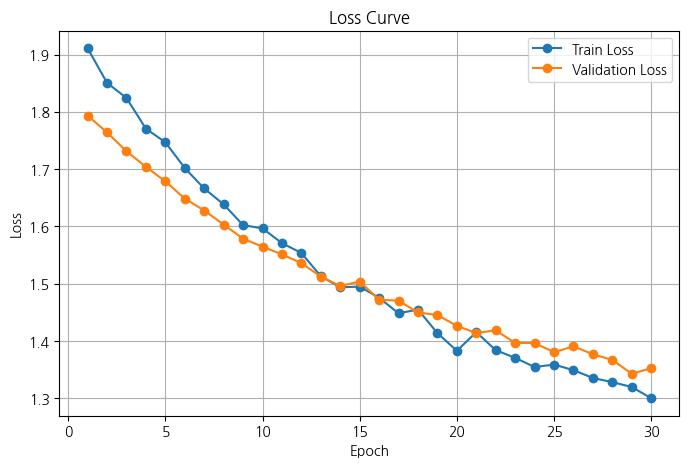

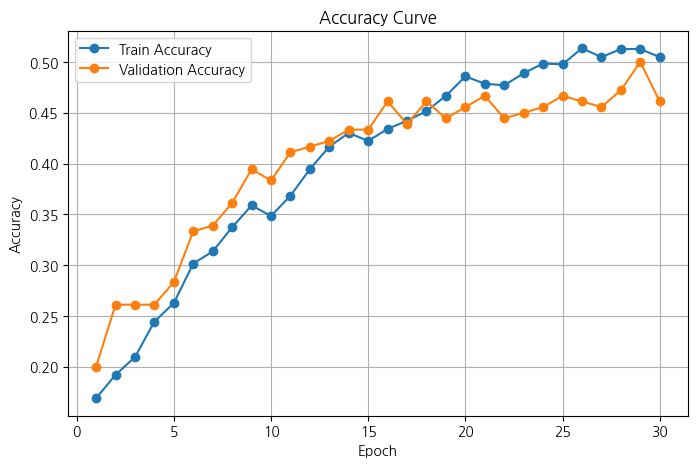

In [ ]:
# === [9] Loss Curve 와 Accuracy Curve 시각화 ===
import matplotlib.pyplot as plt

# Loss Curve 시각화
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig("/content/drive/MyDrive/loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Accuracy Curve 시각화
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_acc"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("/content/drive/MyDrive/accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()


최종 Test Loss 값: 1.317099
최종 Test Set 정확도: 0.513889



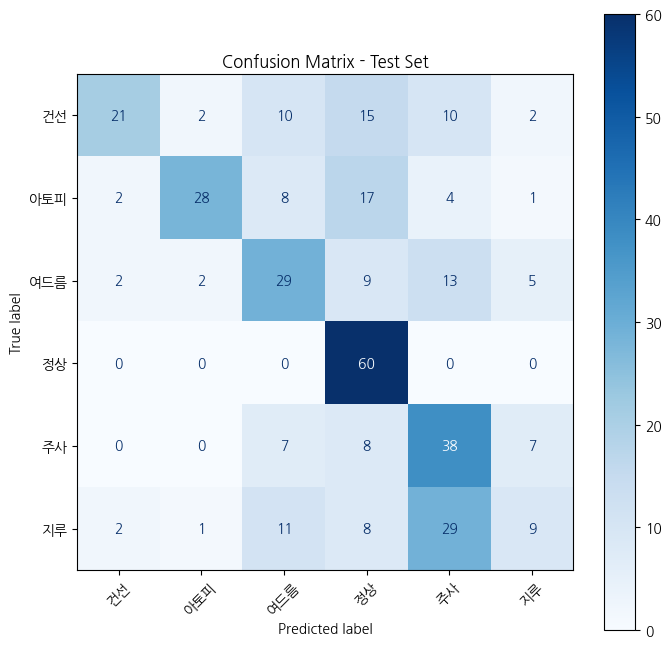

In [ ]:
# === [10] Confusion Matrix 시각화 및 저장 ===
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 최종 Test set 정확도(Accuracy) 계산

print("\n" + "="*50)
print(f"최종 Test Loss 값: {test_loss:.6f}")
print(f"최종 Test Set 정확도: {test_acc:.6f}")
print("="*50 + "\n")

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Test Set")
plt.xticks(rotation=45)

plt.savefig("/content/drive/MyDrive/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### [11] 상세 분류 지표 분석 (Precision, Recall, F1-score, Macro/Micro)

In [ ]:
from sklearn.metrics import classification_report, precision_recall_fscore_support
import pandas as pd

# 1. Classification Report 출력 (클래스별 상세 지표)
print("\n" + "="*60)
print(f"{ '[ 상세 분류 리포트 ]' :^54}")
print("="*60)

# classification_report를 통해 Precision, Recall, F1-score 확인
report = classification_report(all_labels, all_preds, target_names=CLASS_NAMES)
print(report)

# 2. Macro 및 Micro 평균 지표 요약
# precision_recall_fscore_support를 사용하여 수치만 추출
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')
precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(all_labels, all_preds, average='micro')

summary_data = {
    'Metric': ['Precision', 'Recall', 'F1-score'],
    'Micro Average': [f"{precision_micro:.4f}", f"{recall_micro:.4f}", f"{f1_micro:.4f}"],
    'Macro Average': [f"{precision_macro:.4f}", f"{recall_macro:.4f}", f"{f1_macro:.4f}"]
}

summary_df = pd.DataFrame(summary_data)

print("\n" + "="*60)
print(f"{ '[ 평균 지표 요약 (Micro vs Macro) ]' :^50}")
print("="*60)
display(summary_df)i

print("\n* Micro Average: 모든 샘플의 총 개수를 기준으로 계산 (전체 정확도와 동일)")
print("* Macro Average: 각 클래스별 성능을 단순 평균 (클래스별 비중을 무시하므로 소수 클래스 성능 확인에 유리)")


                    [ 상세 분류 리포트 ]                     
              precision    recall  f1-score   support

          건선       0.78      0.35      0.48        60
         아토피       0.85      0.47      0.60        60
         여드름       0.45      0.48      0.46        60
          정상       0.51      1.00      0.68        60
          주사       0.40      0.63      0.49        60
          지루       0.38      0.15      0.21        60

    accuracy                           0.51       360
   macro avg       0.56      0.51      0.49       360
weighted avg       0.56      0.51      0.49       360


          [ 평균 지표 요약 (Micro vs Macro) ]           


,Metric,Micro Average,Macro Average
0,Precision,0.5139,0.5607
1,Recall,0.5139,0.5139
2,F1-score,0.5139,0.4891



* Micro Average: 모든 샘플의 총 개수를 기준으로 계산 (전체 정확도와 동일)
* Macro Average: 각 클래스별 성능을 단순 평균 (클래스별 비중을 무시하므로 소수 클래스 성능 확인에 유리)


In [ ]:
# === [13] 구글 드라이브에 모델 저장 ===
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "mean": MEAN,
    "std": STD,
}, "/content/drive/MyDrive/densenet121_skin_classifier.pth")

print("모델 저장 완료")

모델 저장 완료
